---
title: Ekstraksi Fitur pada Gambar
---

## Pendahuluan

Dalam bidang *computer vision* dan *image processing*, ekstraksi fitur merupakan tahapan krusial yang bertujuan untuk merepresentasikan informasi visual dari suatu gambar ke dalam bentuk vektor numerik. Representasi numerik ini memungkinkan algoritma *machine learning* untuk memahami dan membedakan pola-pola yang terkandung dalam gambar secara kuantitatif.

Pada notebook ini, dilakukan percobaan ekstraksi fitur terhadap dataset gambar yang terdiri dari dua kelas, yaitu **BERANTAKAN** (ruangan yang tidak tertata rapi) dan **RAPI** (ruangan yang tertata dengan baik). Dataset ini dikumpulkan dari beberapa kelompok mahasiswa melalui platform WhatsApp.

Fitur-fitur yang diekstraksi meliputi:

1. **Fitur Statistik Warna (Color Statistics)**:
   - *Mean Red*, *Mean Green*, *Mean Blue*: Nilai rata-rata intensitas piksel untuk masing-masing kanal warna RGB.
   - *Standard Deviation Red*, *Standard Deviation Green*, *Standard Deviation Blue*: Nilai simpangan baku intensitas piksel untuk masing-masing kanal warna RGB, yang merepresentasikan sebaran atau variasi warna dalam gambar.

2. **Fitur Tekstur GLCM (*Gray-Level Co-occurrence Matrix*)**:
   - *Contrast*: Mengukur variasi intensitas lokal antara piksel tetangga.
   - *Dissimilarity*: Mengukur perbedaan rata-rata intensitas antara piksel tetangga.
   - *Homogeneity*: Mengukur kedekatan distribusi elemen GLCM terhadap diagonal GLCM.
   - *Energy*: Mengukur keseragaman tekstur (juga dikenal sebagai *Angular Second Moment*).
   - *Correlation*: Mengukur korelasi linier antara piksel tetangga.
   - *ASM (Angular Second Moment)*: Kuadrat dari *Energy*, mengukur homogenitas tekstur.

   Setiap properti GLCM dihitung pada 4 arah sudut (0°, 45°, 90°, 135°), sehingga menghasilkan 4 nilai per properti. Untuk merangkum karakteristik tekstur secara keseluruhan tanpa bergantung pada satu arah tertentu, diambil nilai **mean** (rata-rata) dan **std** (simpangan baku) dari ke-4 arah tersebut. Oleh karena itu, setiap properti GLCM menghasilkan dua fitur: `mean` dan `std`.

Notebook ini belum melakukan klasifikasi; fokus utamanya adalah pada proses ekstraksi fitur dan penyimpanan hasilnya dalam format CSV.

## Persiapan

### Import Library

Berikut adalah *library* yang digunakan dalam proses ekstraksi fitur gambar:

- **os** dan **glob**: Untuk navigasi direktori dan pencarian file gambar berdasarkan pola *path*.
- **NumPy (`numpy`)**: Untuk komputasi numerik pada matriks piksel gambar.
- **Pandas (`pandas`)**: Untuk membentuk dan menyimpan tabel hasil ekstraksi fitur.
- **Pillow (`PIL`)**: Untuk membaca dan memproses file gambar.
- **scikit-image (`skimage`)**: Untuk menghitung fitur tekstur GLCM (*Gray-Level Co-occurrence Matrix*).
- **Matplotlib (`matplotlib`)**: Untuk visualisasi sampel gambar dari dataset.

In [31]:
import os
import glob

import numpy as np
import pandas as pd
from PIL import Image
from skimage.feature import graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.util import img_as_ubyte
import matplotlib.pyplot as plt

### Konfigurasi Path

Mendefinisikan *path* direktori dataset dan direktori *output* untuk menyimpan hasil ekstraksi.

In [32]:
BASE_DIR = os.path.dirname(os.path.abspath("__file__"))
DATASET_DIR = os.path.join(BASE_DIR, "dataset")
OUTPUT_DIR = os.path.join(BASE_DIR, "output")

os.makedirs(OUTPUT_DIR, exist_ok=True)

KELAS = ["BERANTAKAN", "RAPI"]

print(f"Dataset directory: {DATASET_DIR}")
print(f"Output directory : {OUTPUT_DIR}")

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/home/zkyzors/DevStuff/Assignments/ProyekSainsData/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py", line 3823, in run_code
  File "/tmp/ipykernel_6030/2253204011.py", line 1, in <module>
    BASE_DIR = os.path.dirname(os.path.abspath("__file__"))
                               ~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "<frozen posixpath>", line 381, in abspath
FileNotFoundError: [Errno 2] No such file or directory

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/zkyzors/DevStuff/Assignments/ProyekSainsData/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py", line 2279, in showtraceback
  File "/home/zkyzors/DevStuff/Assignments/ProyekSainsData/.venv/lib/python3.13/site-packages/IPython/core/ultratb.py", line 1300, in structured_traceback
  File "/home/zkyzors/DevStuff/Assignments/ProyekSainsData/.venv/lib/python3.13/site-packages/IPython/core/u

## Eksplorasi Dataset

### Distribusi Jumlah Gambar per Kelas

Menghitung jumlah gambar yang tersedia di setiap kelas dan kelompok untuk memahami distribusi dataset.

In [ ]:
distribusi = []

for kelas in KELAS:
    kelas_dir = os.path.join(DATASET_DIR, kelas)
    kelompok_dirs = sorted(os.listdir(kelas_dir), key=str.lower)

    for kelompok in kelompok_dirs:
        kelompok_path = os.path.join(kelas_dir, kelompok)
        if not os.path.isdir(kelompok_path):
            continue
        gambar_files = glob.glob(os.path.join(kelompok_path, "*.jpeg")) + \
                       glob.glob(os.path.join(kelompok_path, "*.jpg")) + \
                       glob.glob(os.path.join(kelompok_path, "*.png"))
        distribusi.append({
            "Kelas": kelas,
            "Kelompok": kelompok,
            "Jumlah Gambar": len(gambar_files)
        })

df_distribusi = pd.DataFrame(distribusi)
print(df_distribusi.to_string(index=False))
print(f"\nTotal gambar: {df_distribusi['Jumlah Gambar'].sum()}")
print(f"\nDistribusi per kelas:")
print(df_distribusi.groupby("Kelas")["Jumlah Gambar"].sum())

     Kelas   Kelompok  Jumlah Gambar
BERANTAKAN Kelompok 1              7
BERANTAKAN Kelompok 2             15
BERANTAKAN Kelompok 3             15
BERANTAKAN Kelompok 4             15
BERANTAKAN Kelompok 5             15
BERANTAKAN kelompok 6             15
BERANTAKAN kelompok 7             11
      RAPI Kelompok 1              7
      RAPI Kelompok 2             15
      RAPI Kelompok 3              2
      RAPI Kelompok 4             15
      RAPI Kelompok 5             15
      RAPI Kelompok 6             15
      RAPI kelompok 7              4

Total gambar: 166

Distribusi per kelas:
Kelas
BERANTAKAN    93
RAPI          73
Name: Jumlah Gambar, dtype: int64


### Visualisasi Sampel Gambar

Menampilkan beberapa sampel gambar dari masing-masing kelas untuk memberikan gambaran visual terhadap dataset yang digunakan.

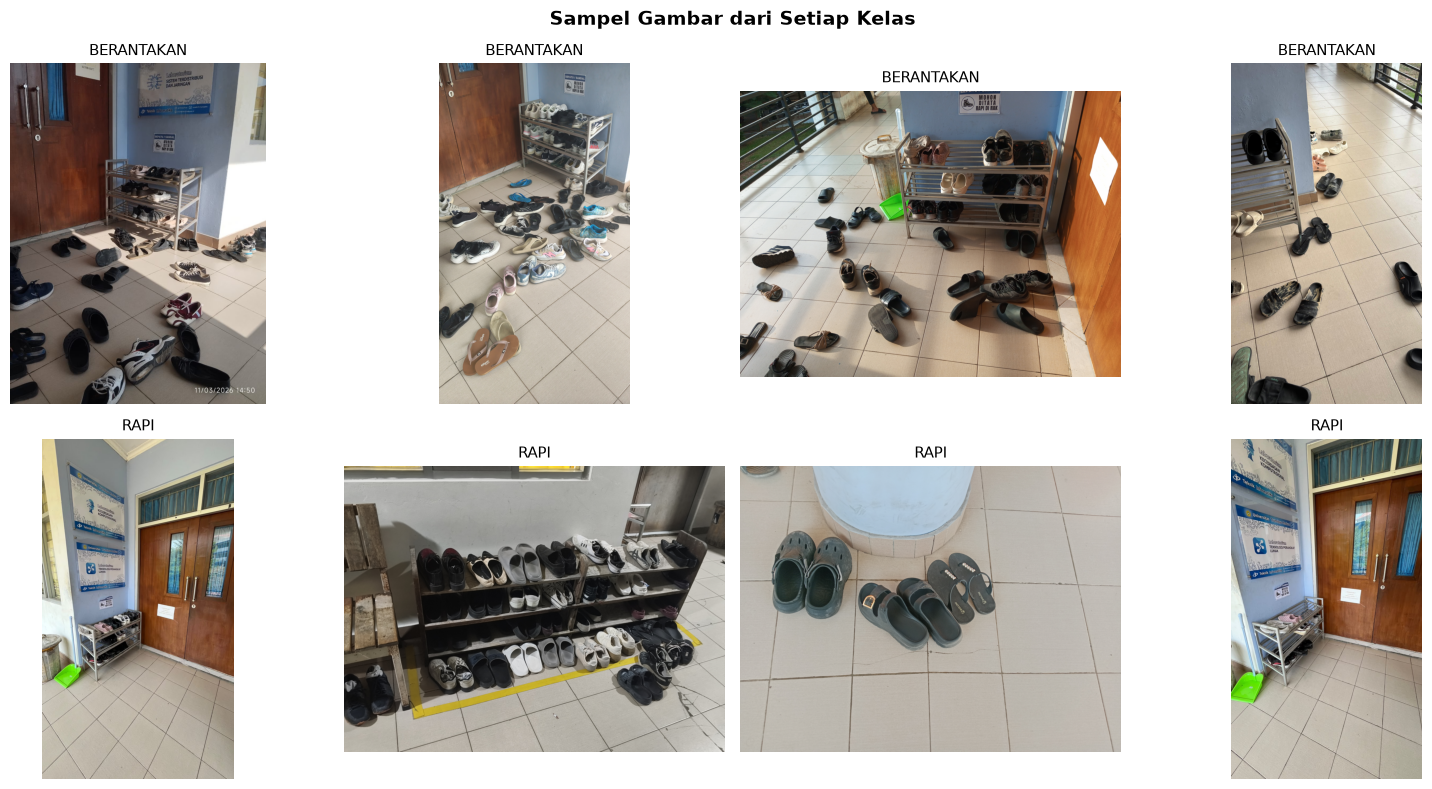

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, kelas in enumerate(KELAS):
    kelas_dir = os.path.join(DATASET_DIR, kelas)
    all_images = []
    for kelompok in sorted(os.listdir(kelas_dir), key=str.lower):
        kelompok_path = os.path.join(kelas_dir, kelompok)
        if not os.path.isdir(kelompok_path):
            continue
        all_images.extend(
            glob.glob(os.path.join(kelompok_path, "*.jpeg")) +
            glob.glob(os.path.join(kelompok_path, "*.jpg")) +
            glob.glob(os.path.join(kelompok_path, "*.png"))
        )

    np.random.seed(42)
    sampel = np.random.choice(all_images, size=min(4, len(all_images)), replace=False)

    for j, img_path in enumerate(sampel):
        img = Image.open(img_path).convert("RGB")
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{kelas}", fontsize=11)
        axes[i, j].axis("off")

plt.suptitle("Sampel Gambar dari Setiap Kelas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Ekstraksi Fitur

### Definisi Fungsi Ekstraksi

Mendefinisikan fungsi untuk mengekstraksi fitur statistik warna (Mean dan Stdev untuk kanal R, G, B) serta fitur tekstur GLCM dari sebuah gambar.

In [ ]:
def ekstraksi_fitur_warna(img_array):
    r, g, b = img_array[:, :, 0], img_array[:, :, 1], img_array[:, :, 2]

    fitur = {
        "mean_r": np.mean(r),
        "mean_g": np.mean(g),
        "mean_b": np.mean(b),
        "std_r": np.std(r),
        "std_g": np.std(g),
        "std_b": np.std(b),
    }

    return fitur

In [ ]:
def ekstraksi_fitur_glcm(img_array):
    gray = rgb2gray(img_array)
    gray_ubyte = img_as_ubyte(gray)

    glcm = graycomatrix(
        gray_ubyte,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properti = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

    fitur = {}
    for prop in properti:
        vals = graycoprops(glcm, prop)
        fitur[f"glcm_{prop}_mean"] = np.mean(vals)
        fitur[f"glcm_{prop}_std"] = np.std(vals)

    return fitur

In [ ]:
def ekstraksi_fitur_gambar(img_path):
    img = Image.open(img_path).convert("RGB")
    img_resized = img.resize((256, 256))
    img_array = np.array(img_resized)

    fitur_warna = ekstraksi_fitur_warna(img_array)
    fitur_glcm = ekstraksi_fitur_glcm(img_array)

    fitur = {**fitur_warna, **fitur_glcm}
    return fitur

### Proses Ekstraksi Fitur untuk Seluruh Dataset

Melakukan iterasi terhadap seluruh gambar di setiap kelas dan kelompok, kemudian mengekstraksi fitur dari masing-masing gambar.

In [ ]:
hasil_ekstraksi = []

for kelas in KELAS:
    kelas_dir = os.path.join(DATASET_DIR, kelas)
    kelompok_dirs = sorted(os.listdir(kelas_dir), key=str.lower)

    for kelompok in kelompok_dirs:
        kelompok_path = os.path.join(kelas_dir, kelompok)
        if not os.path.isdir(kelompok_path):
            continue

        gambar_files = sorted(
            glob.glob(os.path.join(kelompok_path, "*.jpeg")) +
            glob.glob(os.path.join(kelompok_path, "*.jpg")) +
            glob.glob(os.path.join(kelompok_path, "*.png"))
        )

        print(f"[*] Memproses {kelas}/{kelompok} ({len(gambar_files)} gambar)")

        for img_path in gambar_files:
            try:
                fitur = ekstraksi_fitur_gambar(img_path)
                fitur["filename"] = os.path.basename(img_path)
                fitur["kelompok"] = kelompok
                fitur["kelas"] = kelas
                hasil_ekstraksi.append(fitur)
            except Exception as e:
                print(f"    [!] Error pada {os.path.basename(img_path)}: {e}")

print(f"\nTotal gambar berhasil diekstraksi: {len(hasil_ekstraksi)}")

[*] Memproses BERANTAKAN/Kelompok 1 (7 gambar)
[*] Memproses BERANTAKAN/Kelompok 2 (15 gambar)
[*] Memproses BERANTAKAN/Kelompok 3 (15 gambar)
[*] Memproses BERANTAKAN/Kelompok 4 (15 gambar)
[*] Memproses BERANTAKAN/Kelompok 5 (15 gambar)
[*] Memproses BERANTAKAN/kelompok 6 (15 gambar)
[*] Memproses BERANTAKAN/kelompok 7 (11 gambar)
[*] Memproses RAPI/Kelompok 1 (7 gambar)
[*] Memproses RAPI/Kelompok 2 (15 gambar)
[*] Memproses RAPI/Kelompok 3 (2 gambar)
[*] Memproses RAPI/Kelompok 4 (15 gambar)
[*] Memproses RAPI/Kelompok 5 (15 gambar)
[*] Memproses RAPI/Kelompok 6 (15 gambar)
[*] Memproses RAPI/kelompok 7 (4 gambar)

Total gambar berhasil diekstraksi: 166


## Hasil Ekstraksi

### Pembentukan DataFrame

Mengonversi hasil ekstraksi fitur dari seluruh gambar menjadi *DataFrame* Pandas untuk memudahkan analisis dan penyimpanan.

In [ ]:
kolom_urut = [
    "filename", "kelas", "kelompok",
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b",
    "glcm_contrast_mean", "glcm_contrast_std",
    "glcm_dissimilarity_mean", "glcm_dissimilarity_std",
    "glcm_homogeneity_mean", "glcm_homogeneity_std",
    "glcm_energy_mean", "glcm_energy_std",
    "glcm_correlation_mean", "glcm_correlation_std",
    "glcm_ASM_mean", "glcm_ASM_std"
]

df_fitur = pd.DataFrame(hasil_ekstraksi)[kolom_urut]
print(f"Dimensi DataFrame: {df_fitur.shape}")
print(f"Kolom: {list(df_fitur.columns)}")
df_fitur.head(10)

Dimensi DataFrame: (166, 21)
Kolom: ['filename', 'kelas', 'kelompok', 'mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b', 'glcm_contrast_mean', 'glcm_contrast_std', 'glcm_dissimilarity_mean', 'glcm_dissimilarity_std', 'glcm_homogeneity_mean', 'glcm_homogeneity_std', 'glcm_energy_mean', 'glcm_energy_std', 'glcm_correlation_mean', 'glcm_correlation_std', 'glcm_ASM_mean', 'glcm_ASM_std']


,filename,kelas,kelompok,mean_r,mean_g,mean_b,std_r,std_g,std_b,glcm_contrast_mean,...,glcm_dissimilarity_mean,glcm_dissimilarity_std,glcm_homogeneity_mean,glcm_homogeneity_std,glcm_energy_mean,glcm_energy_std,glcm_correlation_mean,glcm_correlation_std,glcm_ASM_mean,glcm_ASM_std
0,WhatsApp Image 2026-11-08 at 17.44.46.jpeg,BERANTAKAN,Kelompok 1,139.664948,137.784714,132.148148,48.335090,50.777582,52.909268,373.242535,...,8.367510,1.525216,0.371941,0.039214,0.029243,0.002581,0.925469,0.020683,0.000862,0.000155
1,WhatsApp Image 2026-11-08 at 17.44.46_1.jpeg,BERANTAKAN,Kelompok 1,147.454788,140.352249,132.804977,56.976392,63.831214,68.074933,533.715275,...,10.524949,2.223873,0.296952,0.038371,0.024080,0.002050,0.930396,0.021775,0.000584,0.000101
2,WhatsApp Image 2026-11-08 at 17.44.46_2.jpeg,BERANTAKAN,Kelompok 1,159.736877,147.375168,132.616470,57.569291,63.769424,66.719835,421.063185,...,8.951308,1.805449,0.328657,0.042729,0.027037,0.002390,0.945594,0.015871,0.000737,0.000132
3,WhatsApp Image 2026-11-08 at 17.44.57.jpeg,BERANTAKAN,Kelompok 1,143.151123,140.705475,134.917648,52.045144,57.637629,61.092668,402.488528,...,8.792847,1.857850,0.337268,0.039173,0.027278,0.002299,0.935847,0.020135,0.000749,0.000129
4,WhatsApp Image 2026-11-08 at 17.44.57_1.jpeg,BERANTAKAN,Kelompok 1,145.888321,143.563614,137.025177,53.278534,60.153817,64.412486,375.728550,...,7.968380,1.624858,0.349802,0.035394,0.032443,0.001736,0.945023,0.017417,0.001056,0.000114
5,WhatsApp Image 2026-11-09 at 10.58.45.jpeg,BERANTAKAN,Kelompok 1,149.809967,137.025894,126.511414,58.796762,63.423189,65.858967,492.396610,...,10.476098,1.376536,0.260622,0.018536,0.017995,0.000759,0.935602,0.015304,0.000324,0.000027
6,WhatsApp Image 2026-11-09 at 10.58.47.jpeg,BERANTAKAN,Kelompok 1,153.074448,138.943100,130.731674,54.282285,61.834353,65.976676,352.521848,...,8.654823,1.202605,0.306931,0.024011,0.024058,0.001082,0.950524,0.012189,0.000580,0.000052
7,IMG_20261104_122321.jpg,BERANTAKAN,Kelompok 2,148.989883,145.024002,141.228760,43.746160,53.328031,58.248138,219.922718,...,5.865715,0.661654,0.425709,0.025192,0.051103,0.001830,0.957610,0.009545,0.002615,0.000186
8,IMG_20261104_122327.jpg,BERANTAKAN,Kelompok 2,148.606720,147.072556,145.104431,42.224454,49.793444,54.878380,225.113508,...,5.844812,0.975749,0.435394,0.035321,0.049430,0.003000,0.950934,0.012584,0.002452,0.000300
9,IMG_20261107_160703.jpg,BERANTAKAN,Kelompok 2,142.863297,114.245972,93.028519,69.396153,67.073321,61.851625,595.912073,...,12.450076,2.433277,0.261944,0.037356,0.022134,0.001963,0.932141,0.020266,0.000494,0.000090


### Statistik Deskriptif

Menampilkan ringkasan statistik deskriptif dari fitur-fitur yang telah diekstraksi untuk memahami distribusi nilainya.

In [ ]:
fitur_numerik = df_fitur.select_dtypes(include=[np.number])
fitur_numerik.describe().T

,count,mean,std,min,25%,50%,75%,max
mean_r,166.0,136.895294,21.050117,60.139572,123.382854,141.166916,150.803688,171.819107
mean_g,166.0,125.777984,18.677237,60.251816,113.085838,126.543541,138.408730,168.611572
mean_b,166.0,115.818135,18.810286,58.460556,102.027718,114.919998,129.525185,162.835861
std_r,166.0,56.972469,9.074177,31.571801,51.373767,57.052101,64.514162,80.662013
std_g,166.0,58.955312,8.060942,33.608945,54.584078,60.153817,64.303767,74.958321
std_b,166.0,59.597727,8.367965,31.649641,54.675924,61.208987,64.975457,76.547959
glcm_contrast_mean,166.0,346.902473,128.600784,56.086021,259.500529,342.894027,422.909406,748.351270
glcm_contrast_std,166.0,98.494043,37.384533,12.506456,70.475866,96.303348,121.930495,211.054531
glcm_dissimilarity_mean,166.0,8.723273,2.111824,3.837421,7.330476,8.649623,10.168190,14.911999
glcm_dissimilarity_std,166.0,1.583417,0.440989,0.410546,1.292243,1.576801,1.850748,2.860695


### Perbandingan Rata-rata Fitur antar Kelas

Membandingkan nilai rata-rata fitur antara kelas BERANTAKAN dan RAPI untuk melihat perbedaan karakteristik visual yang mungkin dapat digunakan sebagai pembeda dalam klasifikasi.

In [ ]:
perbandingan = df_fitur.groupby("kelas")[fitur_numerik.columns.tolist()].mean().T
perbandingan["selisih"] = abs(perbandingan["BERANTAKAN"] - perbandingan["RAPI"])
perbandingan.sort_values("selisih", ascending=False)

kelas,BERANTAKAN,RAPI,selisih
glcm_contrast_mean,359.371133,331.017743,28.353390
mean_r,144.330773,127.422698,16.908075
mean_g,130.427430,119.854716,10.572715
glcm_contrast_std,101.483567,94.685470,6.798097
mean_b,118.612334,112.258401,6.353933
std_r,58.404775,55.147752,3.257023
std_g,60.244308,57.313166,2.931142
std_b,60.872946,57.973133,2.899813
glcm_dissimilarity_mean,8.925869,8.465172,0.460697
glcm_dissimilarity_std,1.606923,1.553471,0.053452


### Visualisasi Perbandingan Fitur Warna

Menampilkan *bar chart* perbandingan rata-rata fitur warna (Mean R, G, B dan Stdev R, G, B) antara kedua kelas.

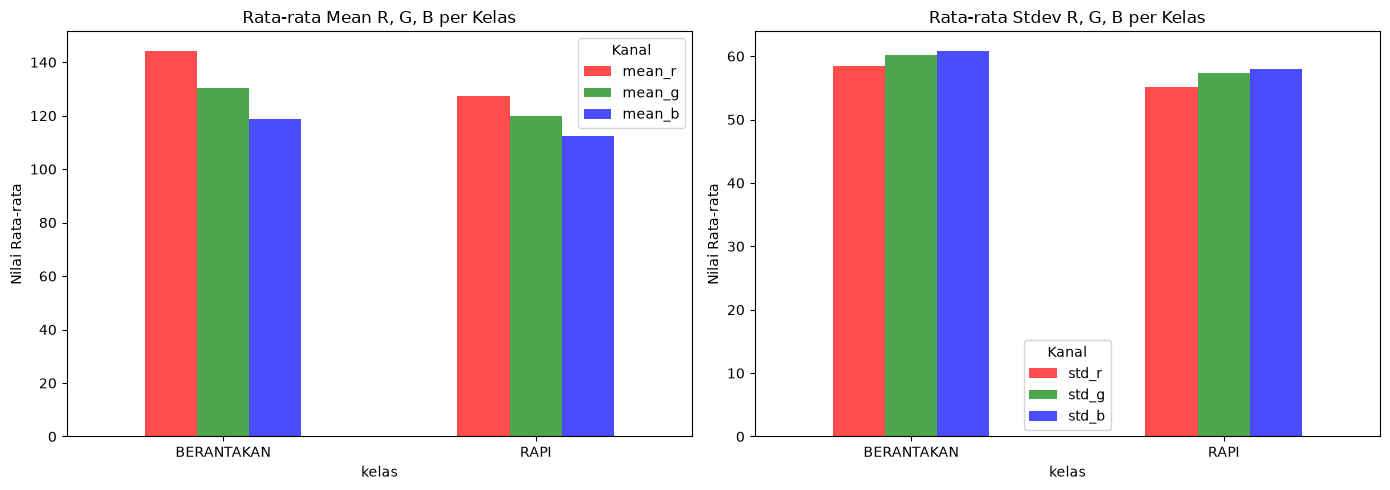

In [ ]:
fitur_warna_cols = ["mean_r", "mean_g", "mean_b", "std_r", "std_g", "std_b"]
df_warna_mean = df_fitur.groupby("kelas")[fitur_warna_cols].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_warna_mean[["mean_r", "mean_g", "mean_b"]].plot(
    kind="bar", ax=axes[0], color=["red", "green", "blue"], alpha=0.7
)
axes[0].set_title("Rata-rata Mean R, G, B per Kelas")
axes[0].set_ylabel("Nilai Rata-rata")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(title="Kanal")

df_warna_mean[["std_r", "std_g", "std_b"]].plot(
    kind="bar", ax=axes[1], color=["red", "green", "blue"], alpha=0.7
)
axes[1].set_title("Rata-rata Stdev R, G, B per Kelas")
axes[1].set_ylabel("Nilai Rata-rata")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(title="Kanal")

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan Fitur GLCM

Menampilkan *bar chart* perbandingan rata-rata fitur tekstur GLCM antara kedua kelas.

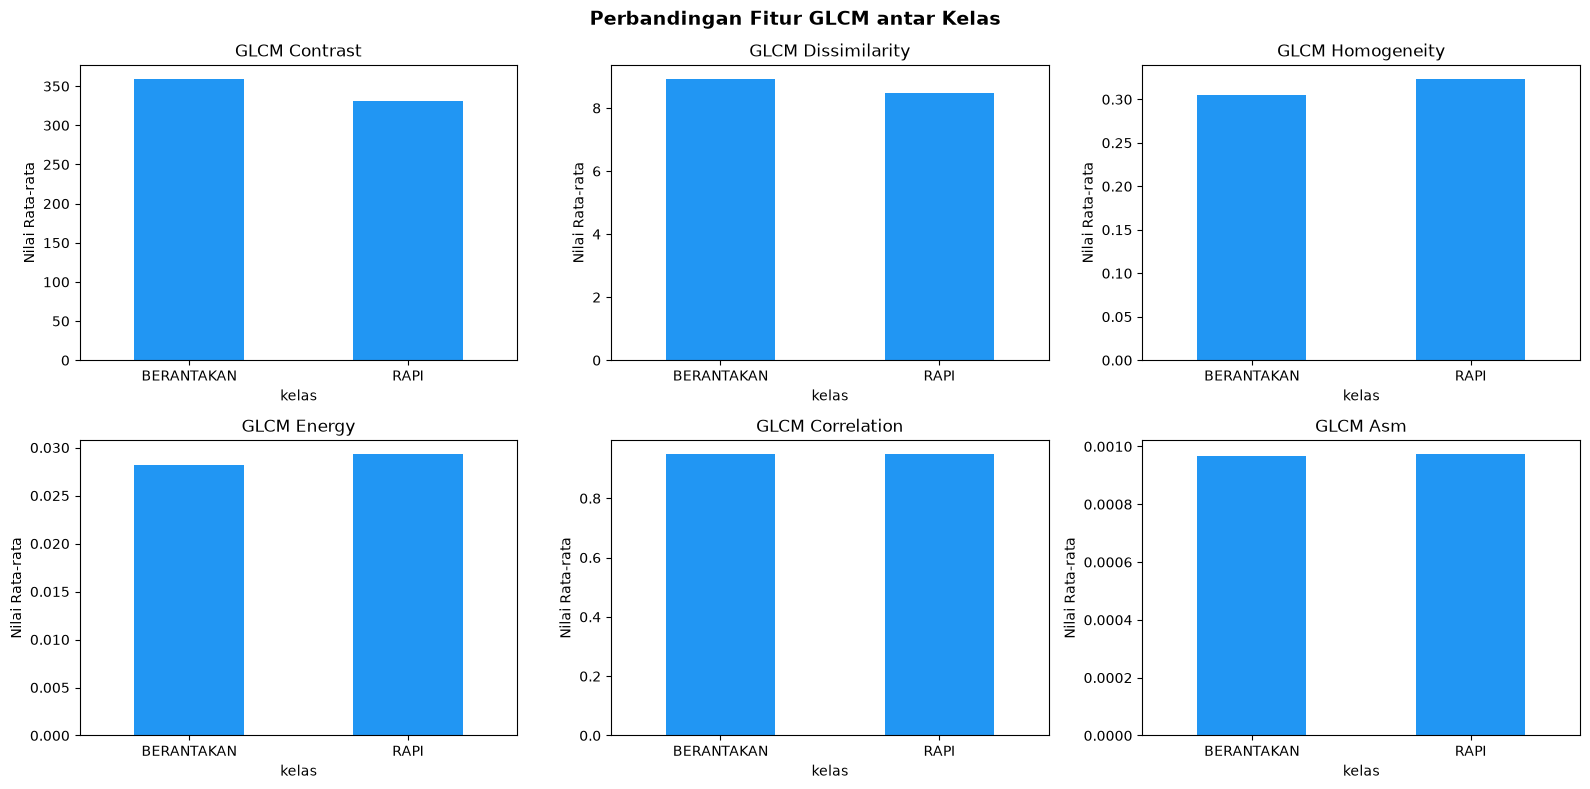

In [ ]:
glcm_mean_cols = [
    "glcm_contrast_mean", "glcm_dissimilarity_mean",
    "glcm_homogeneity_mean", "glcm_energy_mean",
    "glcm_correlation_mean", "glcm_ASM_mean"
]

df_glcm_mean = df_fitur.groupby("kelas")[glcm_mean_cols].mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(glcm_mean_cols):
    label = col.replace("glcm_", "").replace("_mean", "").title()
    df_glcm_mean[[col]].plot(kind="bar", ax=axes[idx], legend=False, color=["#2196F3", "#FF9800"])
    axes[idx].set_title(f"GLCM {label}")
    axes[idx].set_ylabel("Nilai Rata-rata")
    axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=0)

plt.suptitle("Perbandingan Fitur GLCM antar Kelas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Penyimpanan Hasil

Menyimpan DataFrame hasil ekstraksi fitur ke dalam file CSV di direktori `output/` agar dapat digunakan untuk tahap klasifikasi selanjutnya.

In [ ]:
output_path = os.path.join(OUTPUT_DIR, "hasil_ekstraksi_fitur.csv")
df_fitur.to_csv(output_path, index=False)
print(f"Hasil ekstraksi fitur tersimpan di: {output_path}")
print(f"Jumlah baris: {len(df_fitur)}")
print(f"Jumlah kolom: {len(df_fitur.columns)}")

Hasil ekstraksi fitur tersimpan di: /home/zkyzors/DevStuff/Assignments/ProyekSainsData/src/ekstraksi_gambar/output/hasil_ekstraksi_fitur.csv
Jumlah baris: 166
Jumlah kolom: 21


## Kesimpulan

Pada notebook ini telah dilakukan ekstraksi fitur terhadap seluruh gambar dalam dataset yang terdiri dari dua kelas (BERANTAKAN dan RAPI). Fitur yang diekstraksi meliputi 6 fitur statistik warna (Mean dan Stdev untuk kanal R, G, B) serta 12 fitur tekstur GLCM (Mean dan Stdev dari *Contrast*, *Dissimilarity*, *Homogeneity*, *Energy*, *Correlation*, dan *ASM*), menghasilkan total 18 fitur numerik per gambar.

Hasil ekstraksi fitur telah disimpan dalam format CSV dan siap digunakan untuk tahap klasifikasi pada eksperimen selanjutnya.